### generate a braid closure to have a knot for the simulations

In [8]:
from geometry_mnist.knotgen.braidclosure import generate_braid_closure
from geometry_mnist.knotgen.braidclosure import resample_normalize_chain
from geometry_mnist.plotly.plots import plot_pts

word          = [1,-2,1,3,2,2,-4,-3,2,-3,-3,-4] # word must be 1-indexed to hold sign+braid_id. 
n_pts_per_ops = 30
n_resample    = 512

pts_raw       = generate_braid_closure(word, n_pts_per_ops)
pts_resampled = resample_normalize_chain(pts_raw, n_resample)

plot_pts(pts_resampled, kos_len=0.05)

### one simulation step

In [9]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from geometry_mnist.knotgen.chain import ChainProps, construct_far_pairs_mask, construct_sobolev_kernel
from geometry_mnist.knotgen.energy import EnergyWeights
from geometry_mnist.knotgen.sim import SimParams, simstep


# SETUP ========================================================================
pts = torch.as_tensor(pts_resampled, dtype=torch.float64)
K_1 = construct_sobolev_kernel(n_pts=n_resample, reach_percentage=0.02)
K_2 = torch.linalg.matrix_power(K_1, 2)


chain_props = ChainProps(
    resolution=n_resample,
    far_pairs_mask=construct_far_pairs_mask(n_pts=n_resample, excl_percentage=0.02),
    sobolev_k1=K_1,
    sobolev_k2=K_2,
)
e_weights = EnergyWeights( # relaxation: conf=1, bend=1, frep=20, ,  temp=0
    conf=1,
    bend=1,
    frep=20,
)
sim_params = SimParams(
    dt_limit=1e-8,
    temperature=0.00,
)

# RUN ==========================================================================
snapshots = [pts.numpy()]
energies = [np.nan]
eff_steps_avg = [np.nan]

for i in range(5_000):
    
    result = simstep(pts, chain_props, e_weights, sim_params)
    pts = result.pts_next
    
    # logging 
    print(
        f"step: {i+1:05d} | " 
        f"e = {result.e:010.3e} | "
        f"dt_eff = {result.dt_eff:010.3e} | "
        f"dt_reason: {result.dt_eff_reason} | " 
        f"nretries: {result.n_retries:d}")
    snapshots.append(pts.numpy())
    energies.append(result.e)
    eff_steps_avg.append(result.pts_eff_step.norm(dim=1).mean())

step: 00001 | e = 06.327e+02 | dt_eff = 01.000e-08 | dt_reason: limiter | nretries: 0
step: 00002 | e = 05.965e+02 | dt_eff = 01.000e-08 | dt_reason: limiter | nretries: 0
step: 00003 | e = 05.612e+02 | dt_eff = 01.000e-08 | dt_reason: limiter | nretries: 0
step: 00004 | e = 05.303e+02 | dt_eff = 01.000e-08 | dt_reason: limiter | nretries: 0
step: 00005 | e = 05.031e+02 | dt_eff = 01.000e-08 | dt_reason: limiter | nretries: 0
step: 00006 | e = 04.791e+02 | dt_eff = 01.000e-08 | dt_reason: limiter | nretries: 0
step: 00007 | e = 04.580e+02 | dt_eff = 01.000e-08 | dt_reason: limiter | nretries: 0
step: 00008 | e = 04.397e+02 | dt_eff = 01.000e-08 | dt_reason: limiter | nretries: 0
step: 00009 | e = 04.243e+02 | dt_eff = 01.000e-08 | dt_reason: limiter | nretries: 0
step: 00010 | e = 04.116e+02 | dt_eff = 01.000e-08 | dt_reason: limiter | nretries: 0
step: 00011 | e = 04.004e+02 | dt_eff = 01.000e-08 | dt_reason: limiter | nretries: 0
step: 00012 | e = 03.898e+02 | dt_eff = 01.000e-08 | d

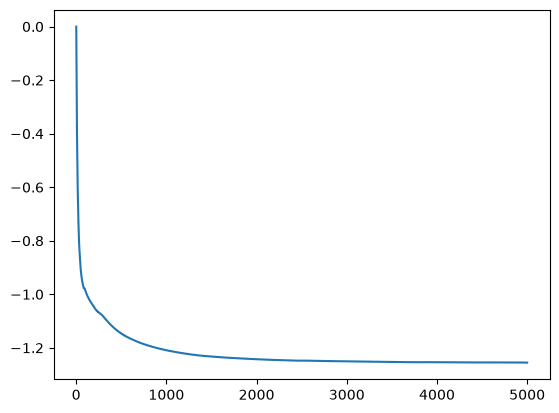

In [10]:
import plotly.graph_objects as go
from geometry_mnist.plotly.plots import plot_scrub

import numpy as np

_ = plt.plot(np.log(np.array(energies) / np.nanmax(energies)))
# plt.plot(np.log(np.array(eff_steps_avg) / np.nanmax(eff_steps_avg)))

plot_scrub(snapshots).show()

In [11]:
from geometry_mnist.paths import ROOT
np.save(ROOT/"data/knot_relaxed.npy", snapshots[-1])